In [ ]:
# import sympy
from sympy import (symbols, expand, Rational, init_printing, sqrt, cos, sin,
                   init_printing, pprint, simplify, factor, trigsimp, collect,
                   cancel, powsimp, expand_power_exp, powdenest)
init_printing()

x, y, z = symbols("x y z")

expr = x + 2*y
e2 = 3*x + y**2
e3 = expr*e2*z
e4 = expand(e3)
# # print(e3)
e4
# print((cos(x)+2).subs(cos(x), 3))


In [ ]:
"""Calculations for m^-"""
x_0, y_0, theta0, x_c, y_c, r_c, rho, x_f, y_f, q = symbols(
    "x_0, y_0, theta0, x_c, y_c, r_c, rho, x_f, y_f, q")

R = r_c + rho
# print(R)

c_0x = x_0 + rho*sin(theta0)
c_0y = y_0 - rho*cos(theta0)

cos1 = (1 - q**2)/(1 + q**2)
sin1 = 2*q/(1 + q**2)

c_1x = x_c + R*sin1
c_1y = y_c - R*cos1

m_minus_x = c_1x - c_0x
m_minus_x = collect(factor(m_minus_x), q)
m_minus_y = c_1y - c_0y
m_minus_y = collect(factor(m_minus_y),q)
# print("m_minus_x =", m_minus_x)
# print("m_minus_y =", m_minus_y)

m_d_minus = factor(m_minus_x**2 + m_minus_y**2)
m_d_minus = collect(m_d_minus, q)

# Simplify m_d_minus by regrouping some constant terms into subterms
m_d_minus_numer, m_d_minus_denom = m_d_minus.as_numer_denom()
# m_d_minus_numer
# m_d_minus_denom
# m_d_minus == m_d_minus_numer/m_d_minus_denom
c_mdm2, c_mdm1, c_mdm0 = symbols("c_mdm2, c_mdm1, c_mdm0")
c_md_min2 = m_d_minus_numer.coeff(q,2)
c_md_min1 = m_d_minus_numer.coeff(q,1)
c_md_min0 = m_d_minus_numer.coeff(q,0)
m_d_minus_numer = m_d_minus_numer - c_md_min2*q**2 - c_md_min1*q - c_md_min0 + c_mdm2*q**2 + c_mdm1*q + c_mdm0
# m_d_minus_numer
# c_md_min2
m_d_minus = m_d_minus_numer/m_d_minus_denom
m_d_minus

# m_d_minus
# m_minus_x
# m_minus_y

In [ ]:
"""Calculations for m^+"""

# sin_thet, cos_thet, sin_delt, cos_delt = symbols("sin_thet, cos_thet, sin_delt, cos_delt")
L = sqrt( (c_1x - x_f)**2 + (c_1y - y_f)**2 )
L = expand(L)
L = symbols("L")
D = sqrt(L**2 - rho**2)
D = symbols('D')

sin_thet = D/L
# print(sin_thet)
cos_thet = rho/L
sin_delt = (y_f - c_1y)/L
# sin_delt = expand(sin_delt)
cos_delt = (x_f - c_1x)/L

x_R = c_1x + rho*(cos_delt*cos_thet - sin_delt*sin_thet)
y_R = c_1y + rho*(sin_delt*cos_thet + cos_delt*sin_thet)

m_plus_x = x_f - x_R
m_plus_x = factor(m_plus_x)
m_plus_x = collect(m_plus_x, [D, L])
m_plus_y = y_f - y_R
m_plus_y = factor(m_plus_y)
m_plus_y = collect(m_plus_y, [D, L])

m_d_plus = m_plus_x**2 + m_plus_y**2
m_d_plus = factor(m_d_plus)
m_d_plus = collect(m_d_plus, q)

# Simplify m_d_plus by regrouping some constant terms into subterms
m_d_plus_numer, m_d_plus_denom = m_d_plus.as_numer_denom()
# m_d_plus_numer
# m_d_plus_denom
m_d_plus_coeff = D**2*rho**2 + L**4 - 2*L**2*rho**2 + rho**4
m_d_plus_numer_simpl = m_d_plus_numer/m_d_plus_coeff
m_d_plus_numer_simpl
c_mdp2, c_mdp1, c_mdp0 = symbols("c_mdp2, c_mdp1, c_mdp0")
c_md_plus2 = m_d_plus_numer_simpl.coeff(q,2)
c_md_plus1 = m_d_plus_numer_simpl.coeff(q,1)
c_md_plus0 = m_d_plus_numer_simpl.coeff(q,0)
# c_md_plus2
# c_md_plus1
# c_md_plus0
substitutions = dict(zip([c_md_plus2, c_md_plus1, c_md_plus0], [c_mdp2, c_mdp1, c_mdp0]))
m_d_plus_numer = m_d_plus_numer.subs(substitutions)
m_d_plus = m_d_plus_numer/m_d_plus_denom
m_d_plus

# m_plus_x
# m_plus_y
# m_d_plus

In [ ]:
"""Combining m^- and m^+, first side of eq 38"""

v_tx = cos1
v_ty = sin1

side1 = (v_tx*m_minus_x + v_ty*m_minus_y)**2
side1_numer, side1_denom = side1.as_numer_denom()
side1_numer = collect(expand(side1_numer), q)
side1 = side1_numer/side1_denom
# side1_numer
# side1_denom
# side1

all_side1 = side1*m_d_plus
all_side1_numer, all_side1_denom = all_side1.as_numer_denom()
all_side1_denom


In [ ]:
"""Combining m^- and m^+, second side of eq 38"""

v_tx = cos1
v_ty = sin1

side2 = (v_tx*m_plus_x + v_ty*m_plus_y)**2
side2_numer, side2_denom = side2.as_numer_denom()
side2_numer = collect(expand(side2_numer), [D, q])
side2 = side2_numer/side2_denom
# side2_denom

all_side2 = side2*m_d_minus
all_side2_numer, all_side2_denom = all_side2.as_numer_denom()
all_side2_denom


In [753]:
"""Combine both sides of the equality"""
# Both sides of eq 38 have the same denominator, so we can cancel it.

side_1_ = all_side1_numer
side_2_ = all_side2_numer

comb = side_1_ - side_2_
comb = collect(expand(comb), [D, q])
# comb = collect(comb, D)

# Isolate the term in D
D_term = comb.coeff(D, 1)
# D_term = collect(D_term, [L, q])
# print(comb)

# Remove the D_term to isolate it
comb_without_D = comb - D*D_term
comb_without_D = collect(comb_without_D, [L,D,q])

# Simplify the D-less term a bit
c_nd_L2, c_nd_L4, c_nd_0 = symbols("c_nd_L2, c_nd_L4, c_nd_0")
c_nd_L2_t = comb_without_D.coeff(L, 2) # constant term multiplying L**2
c_nd_L4_t = comb_without_D.coeff(L, 4) # constant term multiplying L**4
c_nd_0_t = comb_without_D.coeff(L,0).coeff(q,0).coeff(D,0) # constant term multiplying nothing!
comb_without_D = comb_without_D.subs({c_nd_L2_t: c_nd_L2, c_nd_L4_t: c_nd_L4, c_nd_0_t: c_nd_0})

# Simplify the q coefficients that are multiplied by L**4 in the D-less term
c_q1_L4, c_q2_L4, c_q3_L4, c_q4_L4, c_q5_L4, c_q6_L4, c_q7_L4, c_q8_L4, c_q9_L4, c_q10_L4 = symbols(
    "c_q1_L4, c_q2_L4, c_q3_L4, c_q4_L4, c_q5_L4, c_q6_L4, c_q7_L4, c_q8_L4, c_q9_L4, c_q10_L4")
c_q1_L4_t = comb_without_D.coeff(q,1).coeff(L,4)
c_q2_L4_t = comb_without_D.coeff(q,2).coeff(L,4)
c_q3_L4_t = comb_without_D.coeff(q,3).coeff(L,4)
c_q4_L4_t = comb_without_D.coeff(q,4).coeff(L,4)
c_q5_L4_t = comb_without_D.coeff(q,5).coeff(L,4)
c_q6_L4_t = comb_without_D.coeff(q,6).coeff(L,4)
c_q7_L4_t = comb_without_D.coeff(q,7).coeff(L,4)
c_q8_L4_t = comb_without_D.coeff(q,8).coeff(L,4)
c_q9_L4_t = comb_without_D.coeff(q,9).coeff(L,4)
c_q10_L4_t = comb_without_D.coeff(q,10).coeff(L,4)
substitutions_4 = dict(zip([c_q1_L4_t, c_q2_L4_t, c_q3_L4_t, c_q4_L4_t, c_q5_L4_t, c_q6_L4_t, c_q7_L4_t, c_q8_L4_t, c_q9_L4_t, c_q10_L4_t],
                           [c_q1_L4, c_q2_L4, c_q3_L4, c_q4_L4, c_q5_L4, c_q6_L4, c_q7_L4, c_q8_L4, c_q9_L4, c_q10_L4]))
comb_without_D = comb_without_D.subs(substitutions_4)

# Simplify the q coefficients that are multiplied by L**2 in the D-less term
c_q1_L2, c_q2_L2, c_q3_L2, c_q4_L2, c_q5_L2, c_q6_L2, c_q7_L2, c_q8_L2, c_q9_L2, c_q10_L2 = symbols(
    "c_q1_L2, c_q2_L2, c_q3_L2, c_q4_L2, c_q5_L2, c_q6_L2, c_q7_L2, c_q8_L2, c_q9_L2, c_q10_L2")
c_q1_L2_t = comb_without_D.coeff(q,1).coeff(L,2)
c_q2_L2_t = comb_without_D.coeff(q,2).coeff(L,2)
c_q3_L2_t = comb_without_D.coeff(q,3).coeff(L,2)
c_q4_L2_t = comb_without_D.coeff(q,4).coeff(L,2)
c_q5_L2_t = comb_without_D.coeff(q,5).coeff(L,2)
c_q6_L2_t = comb_without_D.coeff(q,6).coeff(L,2)
c_q7_L2_t = comb_without_D.coeff(q,7).coeff(L,2)
c_q8_L2_t = comb_without_D.coeff(q,8).coeff(L,2)
c_q9_L2_t = comb_without_D.coeff(q,9).coeff(L,2)
c_q10_L2_t = comb_without_D.coeff(q,10).coeff(L,2)
substitutions_5 = dict(zip([c_q1_L2_t, c_q2_L2_t, c_q3_L2_t, c_q4_L2_t, c_q5_L2_t, c_q6_L2_t, c_q7_L2_t, c_q8_L2_t, c_q9_L2_t, c_q10_L2_t],
                           [c_q1_L2, c_q2_L2, c_q3_L2, c_q4_L2, c_q5_L2, c_q6_L2, c_q7_L2, c_q8_L2, c_q9_L2, c_q10_L2]))
comb_without_D = comb_without_D.subs(substitutions_5)

# Simplify the q coefficients that are multiplied by NOTHING in the D-less term
c_q1_L0, c_q2_L0, c_q3_L0, c_q4_L0, c_q5_L0, c_q6_L0, c_q7_L0, c_q8_L0, c_q9_L0, c_q10_L0 = symbols(
    "c_q1_L0, c_q2_L0, c_q3_L0, c_q4_L0, c_q5_L0, c_q6_L0, c_q7_L0, c_q8_L0, c_q9_L0, c_q10_L0")
c_q1_L0_t = comb_without_D.coeff(q,1).coeff(L,0)
c_q2_L0_t = comb_without_D.coeff(q,2).coeff(L,0)
c_q3_L0_t = comb_without_D.coeff(q,3).coeff(L,0)
c_q4_L0_t = comb_without_D.coeff(q,4).coeff(L,0)
c_q5_L0_t = comb_without_D.coeff(q,5).coeff(L,0)
c_q6_L0_t = comb_without_D.coeff(q,6).coeff(L,0)
c_q7_L0_t = comb_without_D.coeff(q,7).coeff(L,0)
c_q8_L0_t = comb_without_D.coeff(q,8).coeff(L,0)
c_q9_L0_t = comb_without_D.coeff(q,9).coeff(L,0)
c_q10_L0_t = comb_without_D.coeff(q,10).coeff(L,0)
substitutions_6 = dict(zip([c_q1_L0_t, c_q2_L0_t, c_q3_L0_t, c_q4_L0_t, c_q5_L0_t, c_q6_L0_t, c_q7_L0_t, c_q8_L0_t, c_q9_L0_t, c_q10_L0_t],
                           [c_q1_L0, c_q2_L0, c_q3_L0, c_q4_L0, c_q5_L0, c_q6_L0, c_q7_L0, c_q8_L0, c_q9_L0, c_q10_L0]))
comb_without_D = comb_without_D.subs(substitutions_6)

# Simplify the q coefficients that are multiplied by D**2 in the D-less term
c_q0_D2, c_q1_D2, c_q2_D2, c_q3_D2, c_q4_D2, c_q5_D2, c_q6_D2, c_q7_D2, c_q8_D2, c_q9_D2, c_q10_D2 = symbols(
    "c_q0_D2, c_q1_D2, c_q2_D2, c_q3_D2, c_q4_D2, c_q5_D2, c_q6_D2, c_q7_D2, c_q8_D2, c_q9_D2, c_q10_D2")
c_q0_D2_t = comb_without_D.coeff(D,2).coeff(q,0)
c_q1_D2_t = comb_without_D.coeff(D,2).coeff(q,1)
c_q2_D2_t = comb_without_D.coeff(D,2).coeff(q,2)
c_q3_D2_t = comb_without_D.coeff(D,2).coeff(q,3)
c_q4_D2_t = comb_without_D.coeff(D,2).coeff(q,4)
c_q5_D2_t = comb_without_D.coeff(D,2).coeff(q,5)
c_q6_D2_t = comb_without_D.coeff(D,2).coeff(q,6)
c_q7_D2_t = comb_without_D.coeff(D,2).coeff(q,7)
c_q8_D2_t = comb_without_D.coeff(D,2).coeff(q,8)
c_q9_D2_t = comb_without_D.coeff(D,2).coeff(q,9)
c_q10_D2_t = comb_without_D.coeff(D,2).coeff(q,10)
substitutions_7 = dict(zip([c_q0_D2_t, c_q1_D2_t, c_q2_D2_t, c_q3_D2_t, c_q4_D2_t, c_q5_D2_t, c_q6_D2_t, c_q7_D2_t, c_q8_D2_t, c_q9_D2_t, c_q10_D2_t],
                           [c_q0_D2, c_q1_D2, c_q2_D2, c_q3_D2, c_q4_D2, c_q5_D2, c_q6_D2, c_q7_D2, c_q8_D2, c_q9_D2, c_q10_D2]))
comb_without_D = comb_without_D.subs(substitutions_7)

# Simplify the D_term after removing it from the other term
D_term = collect(D_term, [L, q])
c_d_0, c_d_1, c_d_2, c_d_3, c_d_4, c_d_5, c_d_6, c_d_7, c_d_8, c_d_9, c_d_10 = symbols(
    "c_d_0, c_d_1, c_d_2, c_d_3, c_d_4, c_d_5, c_d_6, c_d_7, c_d_8, c_d_9, c_d_10")
c_d_0_t = D_term.coeff(q, 0)
c_d_1_t = D_term.coeff(q, 1)
c_d_2_t = D_term.coeff(q, 2)
c_d_3_t = D_term.coeff(q, 3)
c_d_4_t = D_term.coeff(q, 4)
c_d_5_t = D_term.coeff(q, 5)
c_d_6_t = D_term.coeff(q, 6)
c_d_7_t = D_term.coeff(q, 7)
c_d_8_t = D_term.coeff(q, 8)
c_d_9_t = D_term.coeff(q, 9)
c_d_10_t = D_term.coeff(q, 10)
substitutions_8 = dict(zip([c_d_0_t, c_d_1_t, c_d_2_t, c_d_3_t, c_d_4_t, c_d_5_t, c_d_6_t, c_d_7_t, c_d_8_t, c_d_9_t, c_d_10_t],
                           [c_d_0, c_d_1, c_d_2, c_d_3, c_d_4, c_d_5, c_d_6, c_d_7, c_d_8, c_d_9, c_d_10]))
D_term = D_term.subs(substitutions_8)

# Also simplify the q terms multiplied by L**2 in the D_term
D_term = collect(D_term, [L, q])
c_dL_0, c_dL_1, c_dL_2, c_dL_3, c_dL_4, c_dL_5, c_dL_6, c_dL_7, c_dL_8, c_dL_9, c_dL_10 = symbols(
    "c_dL_0, c_dL_1, c_dL_2, c_dL_3, c_dL_4, c_dL_5, c_dL_6, c_dL_7, c_dL_8, c_dL_9, c_dL_10")
c_dL_0_t = D_term.coeff(L,2).coeff(q, 0)
c_dL_1_t = D_term.coeff(L,2).coeff(q, 1)
c_dL_2_t = D_term.coeff(L,2).coeff(q, 2)
c_dL_3_t = D_term.coeff(L,2).coeff(q, 3)
c_dL_4_t = D_term.coeff(L,2).coeff(q, 4)
c_dL_5_t = D_term.coeff(L,2).coeff(q, 5)
c_dL_6_t = D_term.coeff(L,2).coeff(q, 6)
c_dL_7_t = D_term.coeff(L,2).coeff(q, 7)
c_dL_8_t = D_term.coeff(L,2).coeff(q, 8)
c_dL_9_t = D_term.coeff(L,2).coeff(q, 9)
c_dL_10_t = D_term.coeff(L,2).coeff(q, 10)
substitutions_9 = dict(zip([c_dL_0_t, c_dL_1_t, c_dL_2_t, c_dL_3_t, c_dL_4_t, c_dL_5_t, c_dL_6_t, c_dL_7_t, c_dL_8_t, c_dL_9_t, c_dL_10_t],
                           [c_dL_0, c_dL_1, c_dL_2, c_dL_3, c_dL_4, c_dL_5, c_dL_6, c_dL_7, c_dL_8, c_dL_9, c_dL_10]))
D_term = D_term.subs(substitutions_9)

# comb
# D_term.coeff(L,2)
D_term
# c_d_0_t
# comb_without_D # about 15s
# c_nd_L2_t
# c_nd_0_t
# c_q7_L4_t
# c_dL_10_t

In [ ]:
"""Square both sides of the equality to only have squared Ds."""
# ABOUT 3m11s!!! THAT'S LONG!

D_term_squared = D_term**2
D_term_final = D**2*D_term_squared
D_term_final = collect(expand(D_term_final), [D, L, q])
# D_term_squared
D_term_final
# Contains D**2 and L**(2,4), multiplying each other

comb_without_D_squared = comb_without_D**2
comb_without_D_squared = collect(expand(comb_without_D_squared), [D,L,q]) # about 
comb_without_D_squared
# contains L**(2,4,6,8) and D**(2,4)
# longest term is the one in D**2 (order 18 q), then the one in L**4 (order 18 q), and D**2*L**4


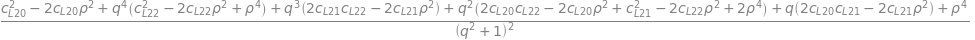

In [763]:
"""Prepare the Ls and Ds before substituting them in the formula"""

# Manage L**2, denom = (q**2 + 1)
L_2 = factor((c_1x - x_f)**2 + (c_1y - y_f)**2)
L_2 = collect(L_2, q)
L_2_numer, L_2_denom = L_2.as_numer_denom()
c_L20, c_L21, c_L22 = symbols("c_L20, c_L21, c_L22")
c_L20_t = L_2_numer.coeff(q, 0)
c_L21_t = L_2_numer.coeff(q, 1)
c_L22_t = L_2_numer.coeff(q, 2)
substitutions_3 = dict(zip([c_L20_t, c_L21_t, c_L22_t], [c_L20, c_L21, c_L22]))
L_2_numer = L_2_numer.subs(substitutions_3)
L_2 = L_2_numer/L_2_denom

# Manage L**4, denom = (q**2 + 1)**2
L_4 = factor(expand(L_2**2))
L_4_numer, L_4_denom = L_4.as_numer_denom()
L_4_numer = collect(expand(L_4_numer), q)
# L_4_denom = expand(L_4_denom)
L_4 = L_4_numer/L_4_denom

# Manage L**6, denom = (q**2 + 1)**3
L_6 = factor(expand(L_2**3))
L_6_numer, L_6_denom = L_6.as_numer_denom()
L_6_numer = collect(expand(L_6_numer), q)
L_6 = L_6_numer/L_6_denom

# Manage L**8, denom = (q**2 + 1)**4
L_8 = factor(expand(L_2**4))
L_8_numer, L_8_denom = L_8.as_numer_denom()
L_8_numer = collect(expand(L_8_numer), q)
L_8 = L_8_numer/L_8_denom

# Manage D**2, denom = (q**2 + 1)
D_2 = L_2 - rho**2
D_2_numer, D_2_denom = D_2.as_numer_denom()
D_2_numer = collect(expand(D_2_numer), q)
D_2 = D_2_numer/D_2_denom
# D_2 = factor((L_2 - rho**2)*(q**2+1))

# Manage D**4, denom = (q**2 + 1)**2
D_4 = factor(expand(D_2**2))
D_4_numer, D_4_denom = D_4.as_numer_denom()
D_4_numer = collect(expand(D_4_numer), q)
D_4 = D_4_numer/D_4_denom

# Maybe do the substitutions and expansions in multiple steps? Unsure yet...
# substitutions_last = dict(zip([L**2, L**4, L**6, L**8, D**2, D**4], [L_2, L_4, L_6, L_8, D_2, D_4]))

# L_2
# L_2_numer
# L_2_denom
# L_4
# L_6
# L_8
# L_4_numer
# L_4_denom
D_2
# D_2_numer
# D_2_denom
D_4


In [ ]:
"""Place the Ls and Ds in the formulas"""

# Place Ls in the D term
D_term_final_L2 = D_term_final.xreplace({L**2: L_2})
D_term_final_L2 = D_term_final_L2*(q**2 + 1)
D_term_final_L2 = collect(cancel(D_term_final_L2), [D,L,q])
D_term_final_L2

# I will need to use cancel, then expand, then collect on the bigger terms



# Need to manage the denominators

# all_together = all_combined.xreplace(substitutions_2) # will replace powers of L separately
# all_together = expand(all_together)
# all_together = collect(all_together, q) # about 8 seconds

In [ ]:
"""Recombine everything together"""

# all_combined = comb_without_D_squared - D_term_final
# all_combined = collect(all_combined, [D,L,q])
# all_combined = expand(all_combined)

# all_combined

In [ ]:
"""Extract all the needed terms"""
# T0 = all_together